# Real-time Object Detection & Tracking (YOLO11 + ByteTrack / BoT-SORT / DeepSORT)

**Before running:** Runtime → Change runtime type → **T4 GPU**. Then run cells top to bottom.

| Part | What it does | Approx. time on T4 |
|---|---|---|
| 1 | Fine-tune YOLO11s on VisDrone (people + vehicles) and report P / R / mAP | ~40-60 min (30 epochs). Lower `EPOCHS` or `FRACTION` to go faster |
| 2 | Download MOT17 (3 sequences) with tracking ground truth | ~5-10 min |
| 3 | Tracker x model comparison: MOTA, IDF1, ID switches, MT/ML, FPS | ~10-15 min |
| 4 | Confidence threshold sweep | ~5 min |
| 5 | Speed benchmark + ONNX export | ~3 min |
| 6 | Demo video with IDs, trails and line counting | ~2 min |
| 7 | Save and download results | - |

Part 1 and Parts 2-4 are independent, so you can run either first.

In [1]:
!nvidia-smi -L
!pip -q install ultralytics motmetrics deep-sort-realtime lap onnx onnxruntime-gpu

GPU 0: Tesla T4 (UUID: GPU-a7098f26-ab35-4a7a-d711-793313e26883)


In [2]:
import os, time, glob, json, shutil, collections, zipfile
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from IPython.display import Image, display, HTML

# motmetrics compatibility shim for NumPy 2.x
if not hasattr(np, "asfarray"):
    np.asfarray = lambda a, dtype=float: np.asarray(a, dtype=dtype)
import motmetrics as mm

from ultralytics import YOLO
from ultralytics.utils import SETTINGS

DEVICE = 0 if torch.cuda.is_available() else "cpu"
WORK = "/content/work"
os.makedirs(WORK, exist_ok=True)
print("device:", DEVICE, "| torch", torch.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
device: 0 | torch 2.14.1+cu130


In [3]:
# OPTIONAL: mount Google Drive so training runs/results survive a runtime disconnect.
# If you use this, change WORK below to a Drive path, e.g. "/content/drive/MyDrive/yolo_track"
MOUNT_DRIVE = False
if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/yolo_track"
    os.makedirs(WORK, exist_ok=True)

## Part 1: Fine-tune the detector on VisDrone

VisDrone has 10 classes (pedestrian, people, bicycle, car, van, truck, tricycle, awning-tricycle, bus, motor). The dataset downloads automatically (~2 GB).

In [4]:
EPOCHS   = 30      # 50+ for a better result
IMGSZ    = 640
BATCH    = 16
FRACTION = 1.0     # use e.g. 0.3 for a quick run on 30% of the training data

det_model = YOLO("yolo11s.pt")           # COCO-pretrained starting point
det_model.train(
    data="VisDrone.yaml", epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, fraction=FRACTION,
    workers=2, device=DEVICE, patience=10, plots=True,
    project=f"{WORK}/runs", name="visdrone_yolo11s", exist_ok=True,
)
TRAIN_DIR = str(det_model.trainer.save_dir)
BEST = str(det_model.trainer.best)
print("best weights:", BEST)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=visdrone_yolo11s, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

In [5]:
# Detection evaluation: precision, recall, mAP@0.5, mAP@0.5:0.95 (+ per class)
best = YOLO(BEST)
m = best.val(data="VisDrone.yaml", split="val", imgsz=IMGSZ, device=DEVICE, plots=True)

print(f"Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")

per_class = pd.DataFrame([
    dict(cls=best.names[c], precision=m.box.p[i], recall=m.box.r[i], AP50=m.box.ap50[i], AP50_95=m.box.ap[i])
    for i, c in enumerate(m.box.ap_class_index)
]).round(3)
display(per_class)
det_summary = dict(precision=m.box.mp, recall=m.box.mr, mAP50=m.box.map50, mAP50_95=m.box.map)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,416,670 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2438.9±1375.9 MB/s, size: 153.1 KB)
val: Scanning /content/datasets/VisDrone/labels/val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 135.2Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 3.6it/s 9.7s
                   all        548      38759       0.51      0.372      0.373      0.218
            pedestrian        520       8844      0.535        0.4      0.406    

,cls,precision,recall,AP50,AP50_95
0,pedestrian,0.535,0.400,0.406,0.179
1,people,0.560,0.277,0.300,0.105
2,bicycle,0.283,0.145,0.120,0.048
3,car,0.697,0.781,0.776,0.531
4,van,0.549,0.432,0.435,0.302
5,truck,0.554,0.363,0.370,0.248
6,tricycle,0.433,0.260,0.249,0.135
7,awning-tricycle,0.284,0.145,0.126,0.077
8,bus,0.685,0.477,0.514,0.367
9,motor,0.521,0.444,0.434,0.184


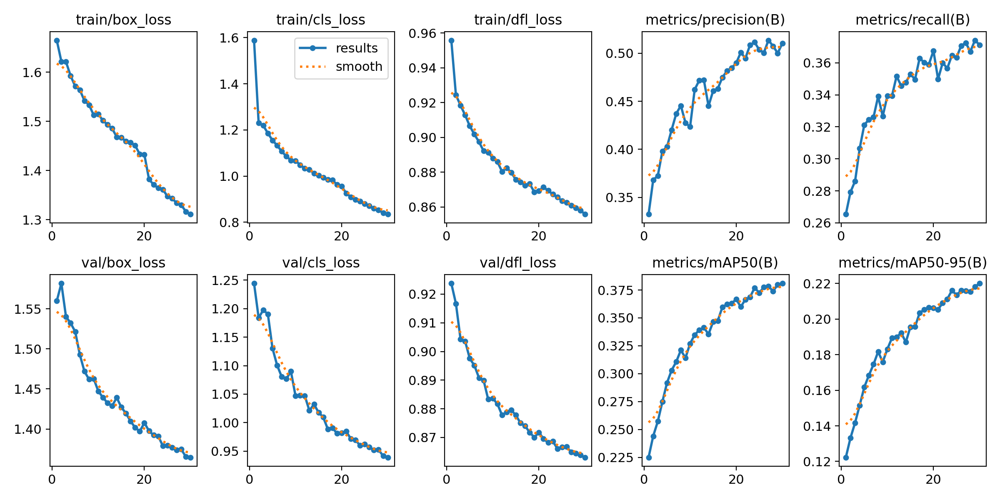

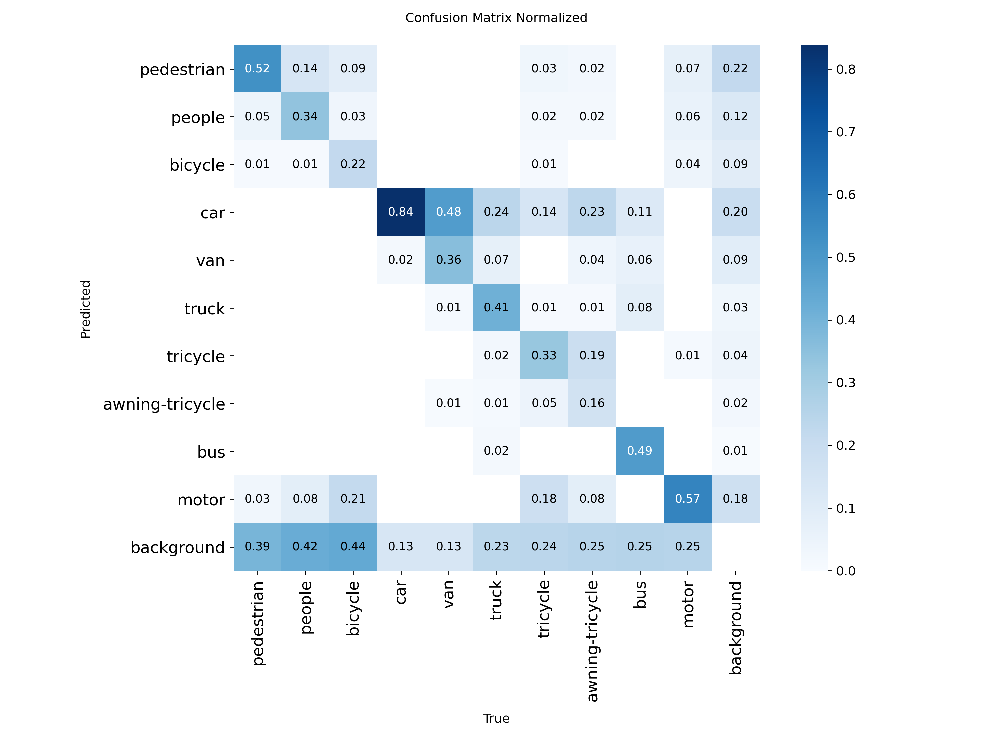

In [6]:
# Curves and confusion matrix
for d, f in [(TRAIN_DIR, "results.png"), (str(m.save_dir), "confusion_matrix_normalized.png"), (str(m.save_dir), "PR_curve.png")]:
    p = os.path.join(d, f)
    if os.path.exists(p):
        display(Image(p, width=800))

# Sample predictions on validation images
val_dir = os.path.join(SETTINGS["datasets_dir"], "VisDrone", "VisDrone2019-DET-val", "images")
imgs = sorted(glob.glob(val_dir + "/*.jpg"))[:6]
if imgs:
    res = best.predict(imgs, imgsz=IMGSZ, conf=0.25, device=DEVICE, verbose=False)
    fig, axs = plt.subplots(2, 3, figsize=(18, 8))
    for ax, r in zip(axs.ravel(), res):
        ax.imshow(r.plot()[..., ::-1]); ax.axis("off")
    plt.tight_layout(); plt.show()

## Part 2: Tracking benchmark data (MOT17)

Downloads the official MOT17 zip (~5.5 GB) and extracts only 3 FRCNN training sequences, which have public ground truth. If `motchallenge.net` is slow, retry the cell (`wget -c` resumes).

In [7]:
MOT_DIR = "/content/MOT17/train"
SEQS = ["MOT17-02-FRCNN", "MOT17-09-FRCNN", "MOT17-04-FRCNN"]

if not all(os.path.isdir(f"{MOT_DIR}/{s}") for s in SEQS):
    !wget -q -c https://motchallenge.net/data/MOT17.zip -O /content/MOT17.zip
    pats = " ".join(f'"MOT17/train/{s}/*"' for s in SEQS)
    !unzip -q -o /content/MOT17.zip {pats} -d /content
    !rm -f /content/MOT17.zip

for s in SEQS:
    n = len(glob.glob(f"{MOT_DIR}/{s}/img1/*.jpg"))
    print(s, n, "frames")

MOT17-02-FRCNN 600 frames
MOT17-09-FRCNN 525 frames
MOT17-04-FRCNN 1050 frames


In [8]:
# ---------- helpers: ground truth, trackers, evaluation ----------
EMPTY = (np.zeros(0, dtype=int), np.zeros((0, 4)))

def seq_frames(seq):
    return sorted(glob.glob(f"{MOT_DIR}/{seq}/img1/*.jpg"))

def load_gt(seq):
    # MOT17 gt.txt: frame, id, x, y, w, h, consider_flag, class, visibility
    g = np.loadtxt(f"{MOT_DIR}/{seq}/gt/gt.txt", delimiter=",")
    g = g[(g[:, 6] == 1) & (g[:, 7] == 1)]          # considered pedestrians only
    out = {}
    for f in np.unique(g[:, 0]).astype(int):
        rows = g[g[:, 0] == f]
        out[f] = (rows[:, 1].astype(int), rows[:, 2:6])
    return out

GT = {s: load_gt(s) for s in SEQS}

def _pack(hyp, f, ids, xyxy):
    if len(ids):
        tlwh = np.stack([xyxy[:, 0], xyxy[:, 1], xyxy[:, 2] - xyxy[:, 0], xyxy[:, 3] - xyxy[:, 1]], 1)
        hyp[f] = (np.asarray(ids).astype(int), tlwh)

def run_ultralytics_tracker(weights, tracker_yaml, seq, conf, classes=(0,), imgsz=1088):
    model = YOLO(weights)                            # fresh model = fresh tracker state per sequence
    hyp, t0 = {}, time.time()
    stream = model.track(source=f"{MOT_DIR}/{seq}/img1", tracker=tracker_yaml, persist=True, stream=True,
                         conf=conf, classes=list(classes), imgsz=imgsz, device=DEVICE, verbose=False)
    for f, r in enumerate(stream, start=1):
        b = r.boxes
        if b.id is not None:
            _pack(hyp, f, b.id.int().cpu().numpy(), b.xyxy.cpu().numpy())
    return hyp, time.time() - t0

def run_deepsort(weights, seq, conf, classes=(0,), imgsz=1088):
    from deep_sort_realtime.deepsort_tracker import DeepSort
    model = YOLO(weights)
    ds = DeepSort(max_age=30, n_init=3, embedder="mobilenet", half=True,
                  embedder_gpu=torch.cuda.is_available())
    hyp, t0 = {}, time.time()
    for f, path in enumerate(seq_frames(seq), start=1):
        img = cv2.imread(path)
        r = model.predict(img, conf=conf, classes=list(classes), imgsz=imgsz, device=DEVICE, verbose=False)[0]
        xyxy, cs = r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()
        dets = [([x1, y1, x2 - x1, y2 - y1], float(c), 0) for (x1, y1, x2, y2), c in zip(xyxy, cs)]
        ids, boxes = [], []
        for t in ds.update_tracks(dets, frame=img):
            if t.is_confirmed() and t.time_since_update == 0:
                ids.append(int(t.track_id)); boxes.append(t.to_ltrb())
        if ids:
            _pack(hyp, f, np.array(ids), np.array(boxes, dtype=float))
    return hyp, time.time() - t0

def run_tracker(name, weights, seq, conf):
    if name == "deepsort":
        return run_deepsort(weights, seq, conf)
    return run_ultralytics_tracker(weights, f"{name}.yaml", seq, conf)

def accumulate(seq, hyp):
    acc = mm.MOTAccumulator(auto_id=True)
    for f in range(1, len(seq_frames(seq)) + 1):
        gids, gboxes = GT[seq].get(f, EMPTY)
        hids, hboxes = hyp.get(f, EMPTY)
        d = mm.distances.iou_matrix(gboxes, hboxes, max_iou=0.5)   # IoU >= 0.5 matching
        acc.update(gids, hids, d)
    return acc

METRICS = ["mota", "idf1", "num_switches", "num_false_positives", "num_misses",
           "mostly_tracked", "mostly_lost", "precision", "recall", "num_objects"]

def evaluate(name, weights, conf, verbose=False):
    accs, secs, nframes = [], 0.0, 0
    for s in SEQS:
        hyp, t = run_tracker(name, weights, s, conf)
        accs.append(accumulate(s, hyp)); secs += t; nframes += len(seq_frames(s))
    summ = mm.metrics.create().compute_many(accs, metrics=METRICS, names=SEQS, generate_overall=True)
    if verbose: display(summ)
    o = summ.loc["OVERALL"]
    return dict(MOTA=o.mota, IDF1=o.idf1, IDSW=int(o.num_switches), FP=int(o.num_false_positives),
                FN=int(o.num_misses), MT=int(o.mostly_tracked), ML=int(o.mostly_lost),
                Prec=o.precision, Rec=o.recall, FPS=nframes / secs)
print("helpers ready")

helpers ready


## Part 3: Tracker x detector-size comparison

Uses COCO-pretrained YOLO11 (person class only) on MOT17. Note: for the ByteTrack/BoT-SORT second association step, the detector confidence is kept low (0.1) and the trackers apply their own thresholds. DeepSORT uses the same detections for a fair comparison.

In [9]:
MODELS   = ["yolo11n.pt", "yolo11s.pt"]            # add "yolo11m.pt" if you have time
TRACKERS = ["bytetrack", "botsort", "deepsort"]
CONF     = 0.1

rows = []
for w in MODELS:
    for trk in TRACKERS:
        print(f"running {w} + {trk} ...")
        r = evaluate(trk, w, CONF)
        rows.append(dict(model=w.replace(".pt", ""), tracker=trk, **r))
results = pd.DataFrame(rows)
fmt = results.copy()
for c in ["MOTA", "IDF1", "Prec", "Rec"]:
    fmt[c] = (fmt[c] * 100).round(1)
fmt["FPS"] = fmt["FPS"].round(1)
display(fmt)

running yolo11n.pt + bytetrack ...
running yolo11n.pt + botsort ...
running yolo11n.pt + deepsort ...


/usr/local/lib/python3.13/dist-packages/deep_sort_realtime/embedder/embedder_pytorch.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


running yolo11s.pt + bytetrack ...
running yolo11s.pt + botsort ...
running yolo11s.pt + deepsort ...


,model,tracker,MOTA,IDF1,IDSW,FP,FN,MT,ML,Prec,Rec,FPS
0,yolo11n,bytetrack,40.1,50.1,264,8917,33643,41,58,80.9,52.9,35.6
1,yolo11n,botsort,40.8,50.7,249,8943,33147,45,57,81.1,53.6,21.1
2,yolo11n,deepsort,32.6,46.1,593,18118,29428,49,43,69.9,58.8,3.6
3,yolo11s,bytetrack,40.3,51.4,242,8742,33670,43,56,81.2,52.9,34.3
4,yolo11s,botsort,41.0,52.9,214,8778,33197,47,57,81.3,53.5,20.8
5,yolo11s,deepsort,36.5,50.5,461,15996,28894,54,34,72.7,59.6,3.5


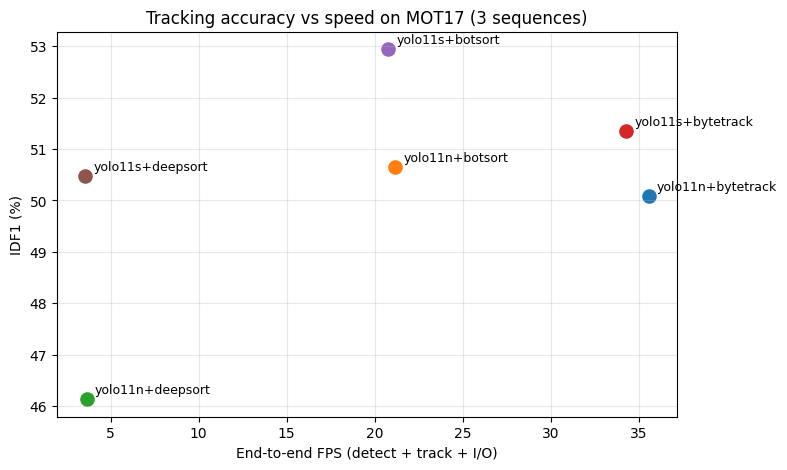

,mota,idf1,num_switches,num_false_positives,num_misses,mostly_tracked,mostly_lost,precision,recall,num_objects
MOT17-02-FRCNN,0.236855,0.377931,100,2660,11420,9,29,0.729152,0.385394,18581
MOT17-09-FRCNN,0.370892,0.492706,50,1809,1491,11,2,0.679426,0.720000,5325
MOT17-04-FRCNN,0.471708,0.565371,92,4273,20759,23,25,0.862476,0.563492,47557
OVERALL,0.403132,0.513500,242,8742,33670,43,56,0.812141,0.528847,71463


In [10]:
# Accuracy vs speed
fig, ax = plt.subplots(figsize=(8, 5))
for _, r in results.iterrows():
    ax.scatter(r.FPS, r.IDF1 * 100, s=90)
    ax.annotate(f"{r.model}+{r.tracker}", (r.FPS, r.IDF1 * 100), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xlabel("End-to-end FPS (detect + track + I/O)"); ax.set_ylabel("IDF1 (%)")
ax.set_title("Tracking accuracy vs speed on MOT17 (3 sequences)"); ax.grid(alpha=.3)
plt.show()

# Detailed per-sequence table for one configuration
_ = evaluate("bytetrack", "yolo11s.pt", CONF, verbose=True)

## Part 4: Confidence-threshold sweep (ByteTrack)

,conf,MOTA,IDF1,IDSW,FP,FN,FPS
0,0.1,0.403,0.514,242,8742,33670,34.107
1,0.2,0.399,0.519,234,7467,35238,34.363
2,0.3,0.391,0.515,207,6113,37176,35.180
3,0.4,0.365,0.504,156,4502,40710,35.707
4,0.5,0.335,0.477,112,3024,44384,35.754


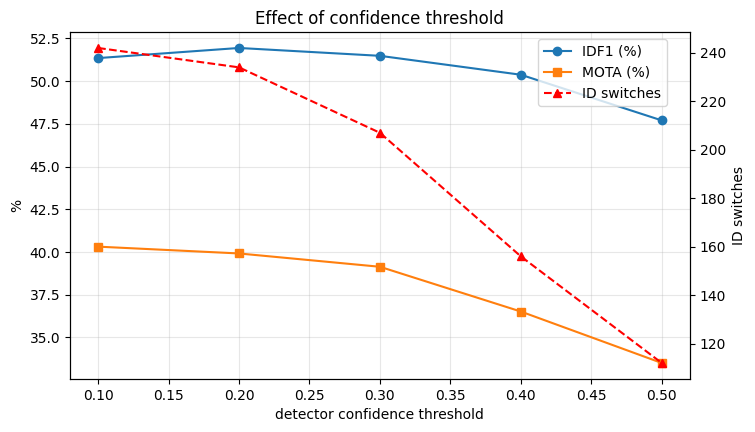

In [11]:
sweep = []
for c in [0.1, 0.2, 0.3, 0.4, 0.5]:
    r = evaluate("bytetrack", "yolo11s.pt", c)
    sweep.append(dict(conf=c, **r))
sweep = pd.DataFrame(sweep)
display(sweep[["conf", "MOTA", "IDF1", "IDSW", "FP", "FN", "FPS"]].round(3))

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(sweep.conf, sweep.IDF1 * 100, "o-", label="IDF1 (%)"); ax1.plot(sweep.conf, sweep.MOTA * 100, "s-", label="MOTA (%)")
ax1.set_xlabel("detector confidence threshold"); ax1.set_ylabel("%"); ax1.grid(alpha=.3)
ax2 = ax1.twinx(); ax2.plot(sweep.conf, sweep.IDSW, "r^--", label="ID switches"); ax2.set_ylabel("ID switches")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88)); plt.title("Effect of confidence threshold"); plt.show()

## Part 5: Speed benchmark and ONNX export

In [12]:
bench_frames = [cv2.imread(p) for p in seq_frames("MOT17-04-FRCNN")[:200]]

def bench(model, frames=bench_frames, warmup=10, imgsz=640):
    for f in frames[:warmup]:
        model.predict(f, imgsz=imgsz, classes=[0], device=DEVICE, verbose=False)
    lat = []
    for f in frames:
        t = time.perf_counter()
        model.predict(f, imgsz=imgsz, classes=[0], device=DEVICE, verbose=False)
        lat.append((time.perf_counter() - t) * 1000)
    return 1000 / np.mean(lat), np.mean(lat)

speed = []
for w in ["yolo11n.pt", "yolo11s.pt"]:
    fps, lat = bench(YOLO(w))
    speed.append(dict(model=w, format="PyTorch", FPS=round(fps, 1), latency_ms=round(lat, 1)))

    onnx_path = YOLO(w).export(format="onnx", imgsz=640, simplify=True)
    fps, lat = bench(YOLO(onnx_path, task="detect"))
    speed.append(dict(model=w, format="ONNX", FPS=round(fps, 1), latency_ms=round(lat, 1)))

# OPTIONAL TensorRT (GPU only; first export takes a few minutes)
RUN_TENSORRT = False
if RUN_TENSORRT:
    for w in ["yolo11n.pt", "yolo11s.pt"]:
        eng = YOLO(w).export(format="engine", half=True, imgsz=640)
        fps, lat = bench(YOLO(eng, task="detect"))
        speed.append(dict(model=w, format="TensorRT FP16", FPS=round(fps, 1), latency_ms=round(lat, 1)))

speed = pd.DataFrame(speed); display(speed)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from 'yolo11n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.4 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 627ms
Prepared 2 packages in 40ms
Installed 2 packages in 5ms
 + colorama==0.4.6
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.2s, saved as 'yolo11n.onnx' (10.2 MB)

Export complete (3.6s)
Res

,model,format,FPS,latency_ms
0,yolo11n.pt,PyTorch,85.7,11.7
1,yolo11n.pt,ONNX,105.9,9.4
2,yolo11s.pt,PyTorch,83.4,12.0
3,yolo11s.pt,ONNX,75.2,13.3


## Part 6: Demo video (boxes, IDs, trails, line-crossing count)

Default uses MOT17-04 frames. To use your own video, set `VIDEO_PATH` (run the upload cell). To track **vehicles** in your own traffic video, use COCO weights with `CLASSES = [2, 3, 5, 7]` (car, motorcycle, bus, truck) or the VisDrone-finetuned `BEST` weights with classes `[3, 4, 5, 8, 9]`.

In [13]:
USE_OWN_VIDEO = False
if USE_OWN_VIDEO:
    from google.colab import files
    up = files.upload()
    VIDEO_PATH = list(up.keys())[0]
else:
    VIDEO_PATH = "/content/mot17_demo_src.mp4"
    frames = seq_frames("MOT17-04-FRCNN")[:450]
    h, w = cv2.imread(frames[0]).shape[:2]
    vw = cv2.VideoWriter(VIDEO_PATH, cv2.VideoWriter_fourcc(*"mp4v"), 30, (w, h))
    for p in frames: vw.write(cv2.imread(p))
    vw.release()
print("source video:", VIDEO_PATH)

source video: /content/mot17_demo_src.mp4


In [20]:
DEMO_WEIGHTS = "yolo11s.pt"
CLASSES      = None            # COCO person; see note above for vehicles
TRACKER      = "bytetrack.yaml"
LINE_FRAC    = 0.55           # horizontal counting line at 55% of frame height

def palette(i):
    rng = np.random.RandomState(int(i) * 7 + 3)
    return tuple(int(x) for x in rng.randint(60, 255, 3))

def make_demo(video, weights, out="/content/demo_raw.mp4", tracker=TRACKER, classes=CLASSES, conf=0.25):
    model = YOLO(weights)
    cap = cv2.VideoCapture(video)
    W, H, FPS = int(cap.get(3)), int(cap.get(4)), cap.get(5) or 30
    cap.release()
    wr = cv2.VideoWriter(out, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
    ly = int(H * LINE_FRAC)
    trails = collections.defaultdict(lambda: collections.deque(maxlen=40))
    last_y, counted, up, down = {}, set(), 0, 0

    for r in model.track(source=video, tracker=tracker, persist=True, stream=True, conf=conf,
                         classes=classes, device=DEVICE, verbose=False):
        frame = r.orig_img.copy()
        cv2.line(frame, (0, ly), (W, ly), (0, 255, 255), 2)
        if r.boxes.id is not None:
            boxes_xyxy = r.boxes.xyxy.cpu().numpy().astype(int)
            track_ids = r.boxes.id.int().cpu().numpy()
            class_indices = r.boxes.cls.int().cpu().numpy()

            for (x1, y1, x2, y2), tid, cls_idx in zip(boxes_xyxy, track_ids, class_indices):
                cx, cy = (x1 + x2) // 2, y2                      # use bottom-center as the anchor
                col = palette(tid)
                trails[tid].append((cx, cy))
                cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)

                # Get class label name
                lbl = model.names.get(cls_idx, "unknown")
                cv2.putText(frame, f"#{tid} {lbl}", (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)

                if len(trails[tid]) > 1:
                    cv2.polylines(frame, [np.array(trails[tid], np.int32)], False, col, 2)
                if tid in last_y and tid not in counted:
                    if last_y[tid] < ly <= cy:   down += 1; counted.add(tid)
                    elif last_y[tid] >= ly > cy: up += 1;   counted.add(tid)
                last_y[tid] = cy
        cv2.rectangle(frame, (0, 0), (260, 70), (0, 0, 0), -1)
        cv2.putText(frame, f"Down: {down}", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        cv2.putText(frame, f"Up:   {up}",   (10, 58), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        wr.write(frame)
    wr.release()
    return out

raw = make_demo(VIDEO_PATH, DEMO_WEIGHTS)
!ffmpeg -y -loglevel error -i {raw} -vcodec libx264 -pix_fmt yuv420p /content/demo.mp4
print("saved /content/demo.mp4")

saved /content/demo.mp4


In [21]:
from base64 import b64encode
data = open("/content/demo.mp4", "rb").read()
if len(data) < 30e6:
    display(HTML(f'<video width=800 controls><source src="data:video/mp4;base64,{b64encode(data).decode()}" type="video/mp4"></video>'))
else:
    print("Video too large to embed; download it from the Files panel or via the cell below.")

## Part 7: Save everything

In [25]:
OUT = "/content/results"; os.makedirs(OUT, exist_ok=True)
results.to_csv(f"{OUT}/tracker_comparison.csv", index=False)
sweep.to_csv(f"{OUT}/conf_sweep.csv", index=False)
speed.to_csv(f"{OUT}/speed_benchmark.csv", index=False)
try:
    per_class.to_csv(f"{OUT}/visdrone_per_class.csv", index=False)
    json.dump({k: float(v) for k, v in det_summary.items()}, open(f"{OUT}/visdrone_detection_metrics.json", "w"), indent=2)
    shutil.copy(BEST, f"{OUT}/best_visdrone_yolo11s.pt")
except NameError:
    print("Part 1 was not run; skipping detection artifacts.")
shutil.copy("/content/demo.mp4", f"{OUT}/demo.mp4")

zp = "/content/results.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f"{OUT}/*"): z.write(f, os.path.basename(f))

from google.colab import files
files.download(zp)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>